# Kick out limit with respect to $\phi_{ini}$

We expect that the kick-out value changes with respect to $\phi_{ini}$ because if the field starts nearby the top of the well, it should need less energy to escape from the well.

In [1]:
import numpy as np
import local
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import os

# Visual settings
%config InlineBackend.figure_format='retina'
%matplotlib inline

if '/Library/TeX/texbin/' not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + '/Library/TeX/texbin/'

plt.rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
plt.rc('text', usetex=True)

In [2]:
# Fixed parameters
logm = -30.5
tf, n = 100, 1
eps = 1e-12
rtol, atol = 1e-5, 1e-7
bphi1_ini = 0.  # initial velocity is always zero

a = np.logspace(-6, 0, 2000)
a_ini = a[0]
z = 1. / a - 1.

z_bins = [
    (20, 10), (30, 20), (40, 30), (50, 40), (60, 50),
    (70, 60), (80, 70), (90, 80), (100, 90)
]

In [3]:
# phi_ini = theta_ini * tf

theta_ini_values = [0.0005, 0.001, 0.005, 0.01]


In [4]:
#Function to search for the kick-out limit

def is_stable(xi, z_start, z_end, phi_ini):
    """Check whether the field stays below the kick-out limit for a given z_bin and phi_ini."""
    phi = solve_ivp(local.EoM_phi, [a[0], 1], [phi_ini, bphi1_ini],
                    t_eval=a, args=[logm, tf, n, xi, eps, z_start, z_end, phi_ini],
                    atol=atol, rtol=rtol, method="RK45")

    if not phi.success:
        return False

    limit_kickout = np.pi * tf
    if np.any(phi.y[0] < -limit_kickout) or np.any(phi.y[0] > limit_kickout):
        return False

    return True


def find_critical_xi(z_start, z_end, phi_ini, xi_min=0.0, xi_max=10.0, tol=1e-6):
    """Binary search for the maximum xi before kick-out, for a given z_bin and phi_ini."""
    low = xi_min
    high = xi_max

    if is_stable(high, z_start, z_end, phi_ini):
        return high

    while (high - low) > tol:
        mid = (low + high) / 2.0
        if is_stable(mid, z_start, z_end, phi_ini):
            low = mid
        else:
            high = mid

    return low

In [5]:
# Searching for the kick-out limit 

all_critical_values = {}

for theta_ini in theta_ini_values:
    critical_values_for_this_phi = {}
    phi_ini = theta_ini * tf

    for z_start, z_end in z_bins:
        xi_crit = find_critical_xi(z_start, z_end, phi_ini, xi_min=0.0, xi_max=10.0, tol=1e-6)
        critical_values_for_this_phi[f"{z_start}-{z_end}"] = xi_crit

    all_critical_values[phi_ini] = critical_values_for_this_phi
    

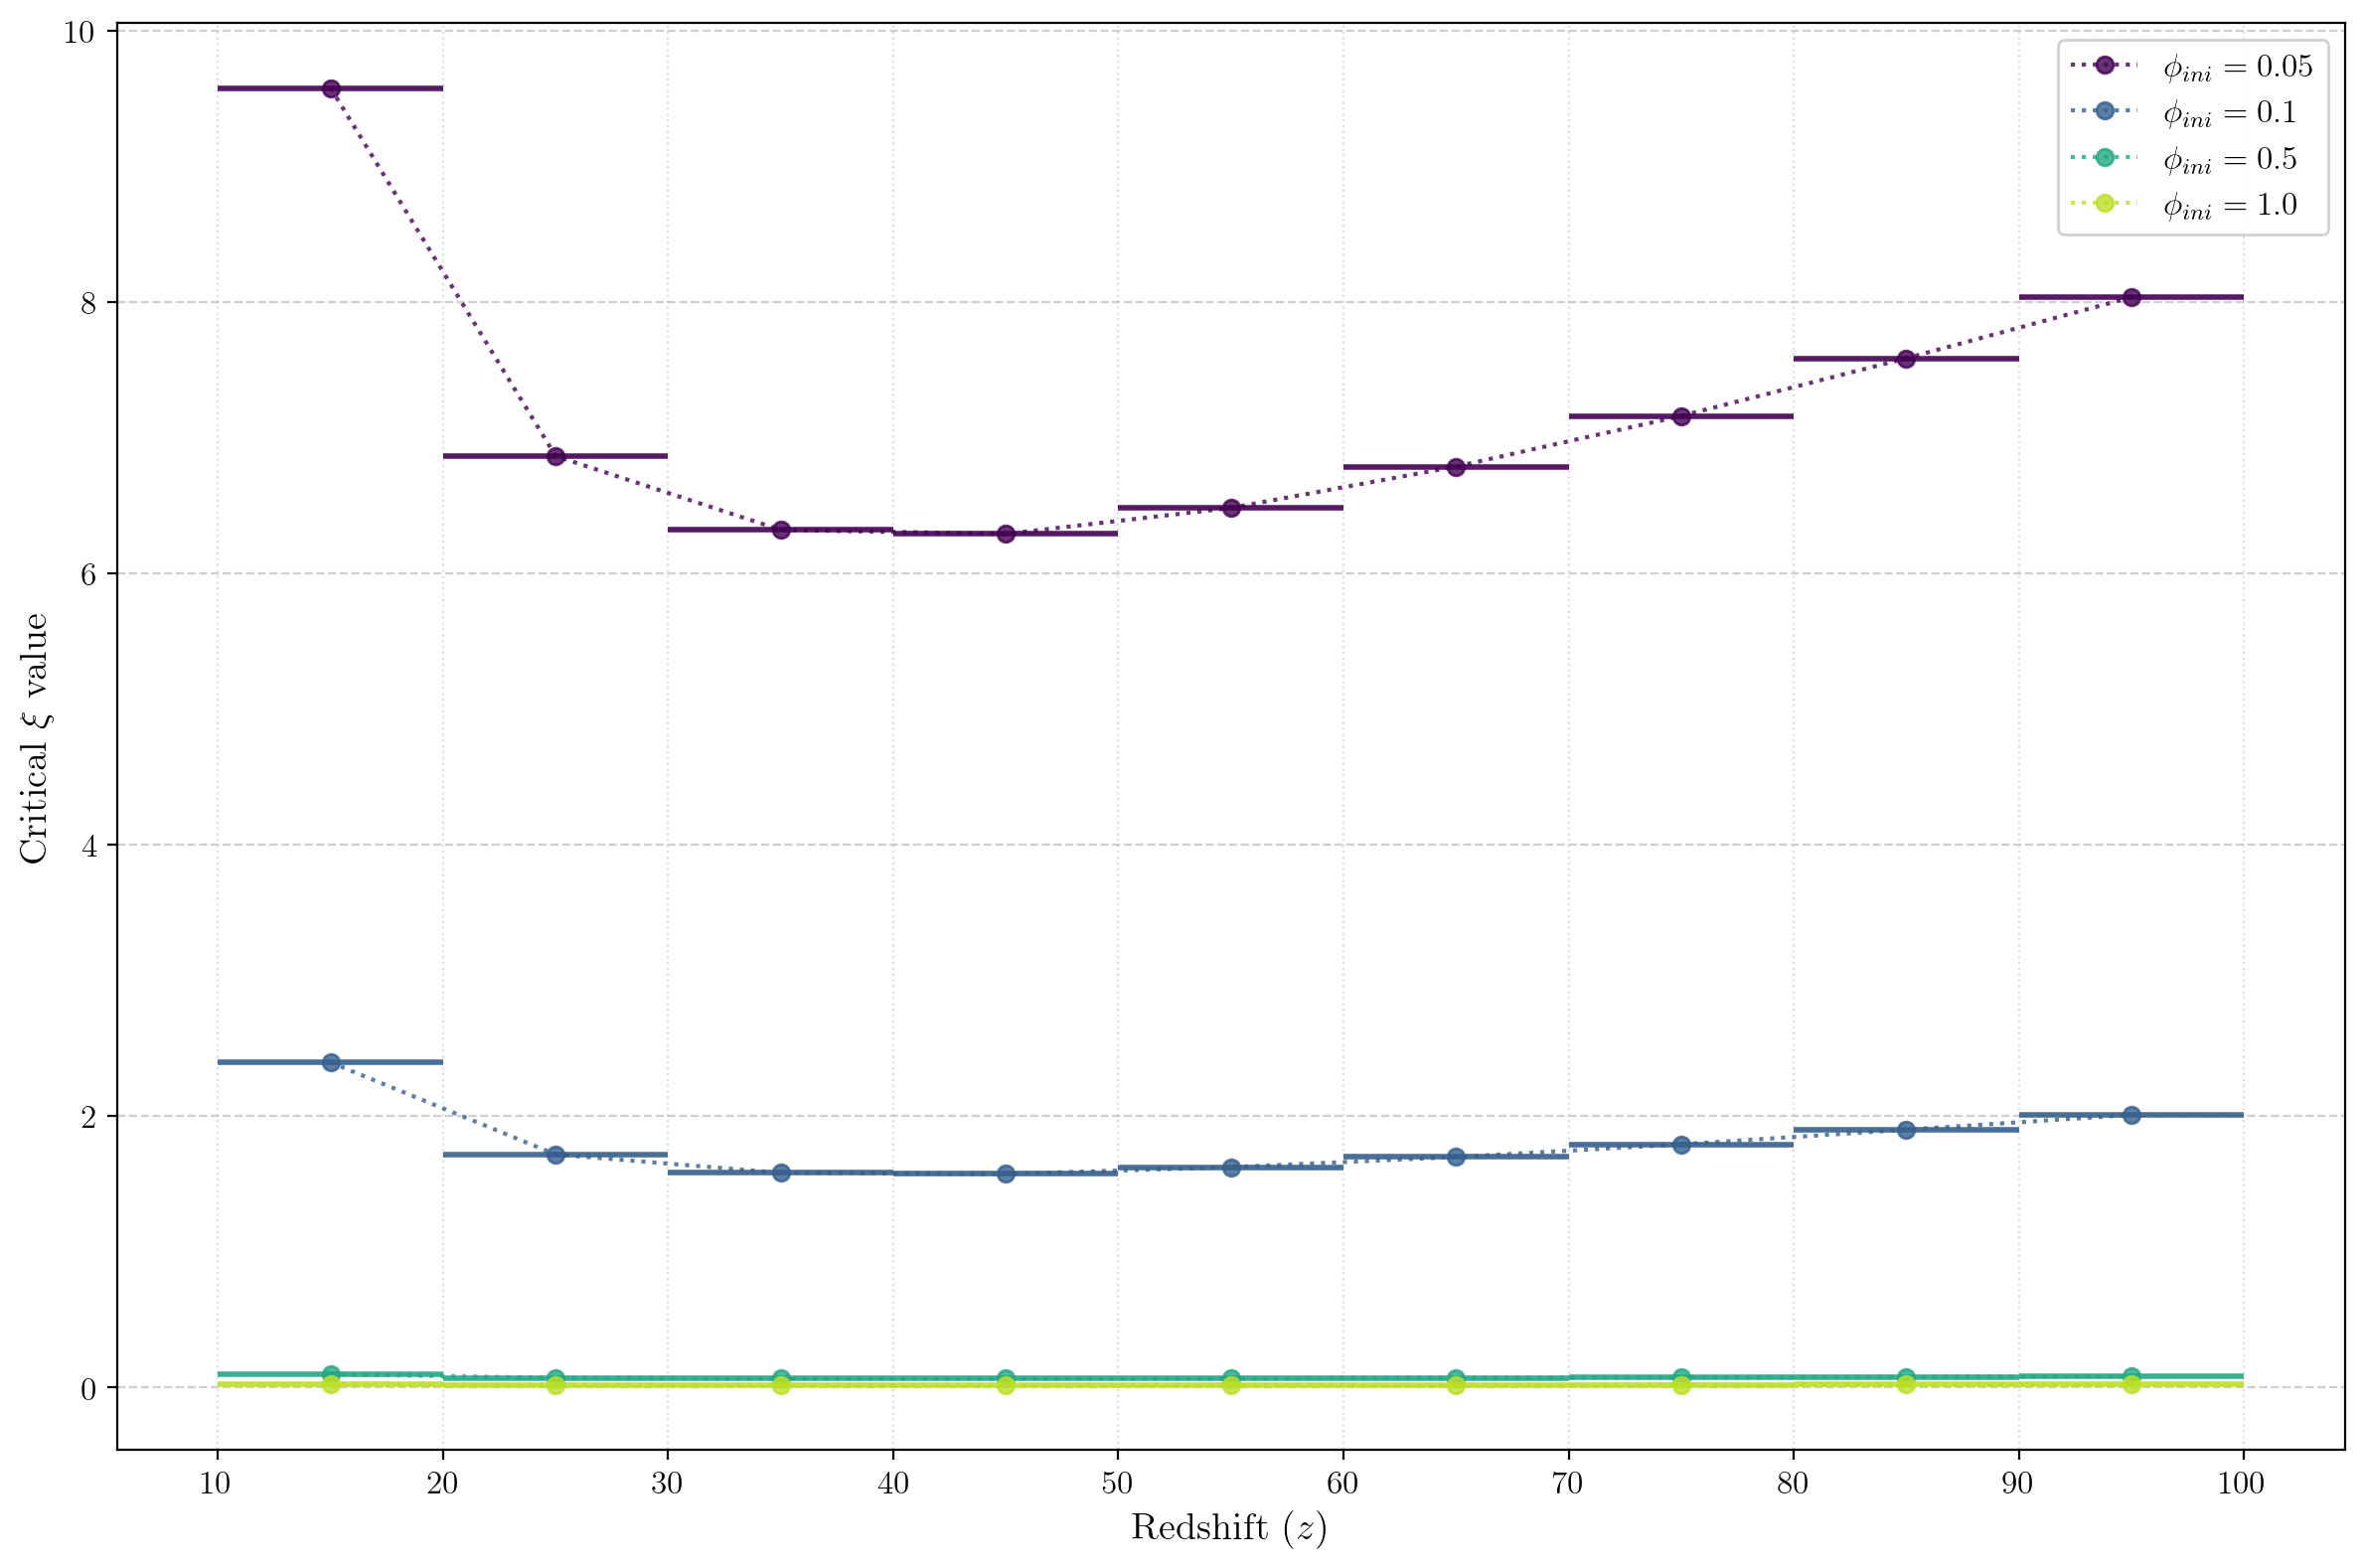

In [6]:
# Plot
z_centers = [(zs + ze) / 2.0 for zs, ze in z_bins]

plt.figure(figsize=(12, 8))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(theta_ini_values)))

for idx, theta_ini in enumerate(theta_ini_values):
    phi_ini = theta_ini * tf
    xi_vals = list(all_critical_values[phi_ini].values())
    c = colors[idx]

    plt.plot(z_centers, xi_vals, marker='o', linestyle=':', color=c,
             markersize=6, linewidth=1.5, alpha=0.8, label=rf'$\phi_{{ini}} = {phi_ini}$')

    for (z_start, z_end), xi in zip(z_bins, xi_vals):
        plt.hlines(y=xi, xmin=min(z_start, z_end), xmax=max(z_start, z_end),
                   color=c, linestyle='-', linewidth=2.0, alpha=0.9)

plt.xlabel('Redshift ($z$)', fontsize=14)
plt.ylabel(r'Critical $\xi$ value', fontsize=14)
plt.xticks(np.arange(10, 101, 10), fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.grid(axis='x', linestyle=':', alpha=0.4)
plt.legend(fontsize=12, loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.savefig("critical_xi_all_phi_ini.png", dpi=300)
plt.show()